# Product Line Profitability & Margin Performance Analysis

## Nassau Candy Distributor

This project analyzes product profitability, sales performance, regional performance, and time-based trends using Exploratory Data Analysis and Machine Learning.

## Background and Context

For distributors like Nassau Candy, sales volume alone may not provide a complete picture of business performance. A product may sell in high volume but generate relatively lower profit, while another product with lower sales volume may contribute more to overall gross profit or profit margin.

Therefore, it is important to analyze both sales performance and profitability to understand which products are truly contributing to the business.

This project focuses on identifying:

- Which products generate the highest sales and gross profit
- Which products achieve higher profit margins
- Which divisions contribute most to overall profitability
- Which regions and time periods perform better
- How profitability categories can be identified using machine learning

The analysis can help support business decisions related to product focus, pricing, sourcing, cost management, and product rationalization.

## Problem Statement

The organization needs better visibility into product-level and division-level profitability. Sales volume alone does not provide a complete picture of business performance, as products with high sales or unit volume may not always generate the highest gross profit or profit margin.

The project addresses the following business questions:

- Which product lines generate the highest gross profit and profit margin?
- Are the products with high sales and unit volume also the most profitable?
- How does profitability vary across different product divisions?
- Which products have relatively lower profit margins and may represent potential margin risk?

The analysis uses sales, cost, gross profit, units sold, and profit margin to identify differences in product and division performance and provide insights for better profitability-focused decision making.

## 1. Import Libraries

In [119]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 2. Load Dataset

In [120]:
df = pd.read_csv('Nassau Candy Distributor.csv')

## 3. Data Understanding

In [121]:
print("Rows: ",df.shape[0])
print("Columns: ",df.shape[1])

Rows:  10194
Columns:  18


In [122]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90


In [123]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Country/Region', 'City', 'State/Province',
       'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name',
       'Sales', 'Units', 'Gross Profit', 'Cost'],
      dtype='object')

In [124]:
df.dtypes 

Row ID              int64
Order ID           object
Order Date         object
Ship Date          object
Ship Mode          object
Customer ID         int64
Country/Region     object
City               object
State/Province     object
Postal Code        object
Division           object
Region             object
Product ID         object
Product Name       object
Sales             float64
Units               int64
Gross Profit      float64
Cost              float64
dtype: object

## 4. Data Cleaning

In [125]:
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Division          0
Region            0
Product ID        0
Product Name      0
Sales             0
Units             0
Gross Profit      0
Cost              0
dtype: int64

In [126]:
df.duplicated().sum()

0

In [127]:
df.describe()

,Row ID,Customer ID,Sales,Units,Gross Profit,Cost
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,134468.961154,13.908537,3.791838,9.166451,4.742087
std,2942.898656,20231.483007,11.341020,2.228317,6.643740,5.061647
min,1.000000,100006.000000,1.250000,1.000000,0.250000,0.600000
25%,2549.250000,117212.000000,7.200000,2.000000,4.900000,2.400000
50%,5097.500000,133550.000000,10.800000,3.000000,7.470000,3.600000
75%,7645.750000,152051.000000,18.000000,5.000000,12.250000,5.700000
max,10194.000000,192314.000000,260.000000,14.000000,130.000000,130.000000


In [128]:
print("Division:")
print(df['Division'].unique())

print("\nRegion:")
print(df['Region'].unique())

print("\nShip Mode:")
print(df['Ship Mode'].unique())

print("\nProduct Names:")
print(df["Product Name"].unique())


Division:
['Chocolate' 'Other' 'Sugar']

Region:
['Interior' 'Atlantic' 'Gulf' 'Pacific']

Ship Mode:
['Standard Class' 'First Class' 'Second Class' 'Same Day']

Product Names:
['Wonka Bar - Milk Chocolate' 'Wonka Bar - Triple Dazzle Caramel'
 'Wonka Bar - Nutty Crunch Surprise' 'Wonka Bar -Scrumdiddlyumptious'
 'Wonka Bar - Fudge Mallows' 'Wonka Gum' 'Kazookles' 'Lickable Wallpaper'
 'Fizzy Lifting Drinks' 'Laffy Taffy' 'SweeTARTS' 'Nerds' 'Hair Toffee'
 'Everlasting Gobstopper' 'Fun Dip']


In [129]:
df["Product Name"] = df["Product Name"].str.strip()
df["Division"] = df["Division"].str.strip()

In [130]:
print(df['Order Date'].dtype)
print(df['Ship Date'].dtype)

object
object


In [131]:
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst = True)
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst = True)

print(df['Order Date'].dtype)
print(df['Ship Date'].dtype)

datetime64[ns]
datetime64[ns]


In [132]:
print("Invalid Order Dates: ", df['Order Date'].isna().sum())
print("Invalid Ship Dates: ", df['Ship Date'].isna().sum())

Invalid Order Dates:  0
Invalid Ship Dates:  0


In [133]:
print("Order Date Range:")
print(df["Order Date"].min(), "to", df["Order Date"].max())

print("\nShip Date Range:")
print(df['Ship Date'].min(), "to", df['Ship Date'].max())

Order Date Range:
2024-01-02 00:00:00 to 2025-12-31 00:00:00

Ship Date Range:
2026-06-30 00:00:00 to 2030-06-28 00:00:00


In [134]:
df[['Order Date','Ship Date']].head(10)

,Order Date,Ship Date
0,2024-01-03,2026-06-30
1,2024-01-04,2026-07-01
2,2024-01-04,2026-07-01
3,2024-01-04,2026-07-01
4,2024-01-05,2026-07-05
5,2024-01-06,2026-07-03
6,2024-01-06,2026-07-03
7,2024-01-06,2026-06-30
8,2024-01-06,2026-07-03
9,2024-01-06,2026-07-03


In [135]:
df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

df["Shipping Days"].describe()

count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Shipping Days, dtype: float64

Shipping duration was examined as part of data validation. The dataset contains unusually large shipping durations due to the relationship between the recorded order and ship dates. Since these values may not represent realistic delivery durations, Shipping Days was not used as a major feature in the profitability analysis or machine learning model.

In [136]:
df['Shipping Days'].value_counts().head(10)

Shipping Days
1273    1326
1274    1035
1639     896
1640     657
1275     612
1271     610
908      591
909      519
1272     456
1637     449
Name: count, dtype: int64

In [137]:
df[['Sales', 'Units', 'Gross Profit', 'Cost']].describe()

,Sales,Units,Gross Profit,Cost
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,13.908537,3.791838,9.166451,4.742087
std,11.341020,2.228317,6.643740,5.061647
min,1.250000,1.000000,0.250000,0.600000
25%,7.200000,2.000000,4.900000,2.400000
50%,10.800000,3.000000,7.470000,3.600000
75%,18.000000,5.000000,12.250000,5.700000
max,260.000000,14.000000,130.000000,130.000000


In [138]:
print("Missing Units:", df["Units"].isnull().sum())

Missing Units: 0


In [139]:
print("Negative Sales:",(df['Sales'] < 0).sum())
print("Negative Units:",(df['Units'] < 0).sum())
print("Negative Gross Profit:",(df['Gross Profit'] < 0).sum())
print("Negative Cost:",(df['Cost'] < 0).sum())

print("\nZero Sales:",(df['Sales'] == 0).sum())
print("Zero Units:",(df['Units'] == 0).sum())
print("Zero Gross Profit:",(df['Gross Profit'] == 0).sum())
print("Zero Cost:",(df['Cost'] == 0).sum())

Negative Sales: 0
Negative Units: 0
Negative Gross Profit: 0
Negative Cost: 0

Zero Sales: 0
Zero Units: 0
Zero Gross Profit: 0
Zero Cost: 0


#### Data Cleaning Summary:

- No missing values were found.
- No duplicate records were found.
- Date columns were converted to datetime format.
- No invalid dates were identified.
- Sales, Units, Gross Profit, and Cost contained no negative values.
- Zero-value checks did not identify problematic records.

## 5. Feature Engineering

In [140]:
df["Profit Margin"] = df['Gross Profit'] / df['Sales'] * 100

In [141]:
df["Profit per Unit"] = df["Gross Profit"] / df["Units"]

In [142]:
df[['Sales', 'Gross Profit', 'Profit Margin', 'Profit per Unit']].head(10)

,Sales,Gross Profit,Profit Margin,Profit per Unit
0,6.50,4.22,64.923077,2.11
1,7.50,4.90,65.333333,2.45
2,10.47,7.47,71.346705,2.49
3,10.80,7.50,69.444444,2.50
4,11.25,7.35,65.333333,2.45
5,32.40,22.50,69.444444,2.50
6,7.50,4.90,65.333333,2.45
7,9.75,6.33,64.923077,2.11
8,6.98,4.98,71.346705,2.49
9,13.00,8.44,64.923077,2.11


In [143]:
df['Profit Margin'].describe()

count    10194.000000
mean        66.514045
std          6.721012
min          7.692308
25%         65.333333
50%         66.666667
75%         69.444444
max         80.000000
Name: Profit Margin, dtype: float64

In [144]:
df['Year'] = df['Order Date'].dt.year

In [145]:
df[['Order Date', 'Year']].head(10)

,Order Date,Year
0,2024-01-03,2024
1,2024-01-04,2024
2,2024-01-04,2024
3,2024-01-04,2024
4,2024-01-05,2024
5,2024-01-06,2024
6,2024-01-06,2024
7,2024-01-06,2024
8,2024-01-06,2024
9,2024-01-06,2024


In [146]:
df["Month"] = df['Order Date'].dt.month

In [147]:
df[['Order Date', 'Month']].head(10)

,Order Date,Month
0,2024-01-03,1
1,2024-01-04,1
2,2024-01-04,1
3,2024-01-04,1
4,2024-01-05,1
5,2024-01-06,1
6,2024-01-06,1
7,2024-01-06,1
8,2024-01-06,1
9,2024-01-06,1


In [148]:
df['Quarter'] = df['Order Date'].dt.quarter

In [149]:
df[['Order Date', 'Quarter']].head(10)

,Order Date,Quarter
0,2024-01-03,1
1,2024-01-04,1
2,2024-01-04,1
3,2024-01-04,1
4,2024-01-05,1
5,2024-01-06,1
6,2024-01-06,1
7,2024-01-06,1
8,2024-01-06,1
9,2024-01-06,1


Profit Margin was calculated to measure profitability relative to sales. Year, Month, and Quarter were extracted from Order Date to support time-based analysis.

## 6. Key Performance Indicators (KPIs)

In [150]:
total_sales = df["Sales"].sum()
total_profit = df["Gross Profit"].sum()

product_kpis = df.groupby("Product Name").agg(
    Sales=("Sales", "sum"),
    Gross_Profit=("Gross Profit", "sum"),
    Units=("Units", "sum")
).reset_index()

product_kpis["Gross Margin (%)"] = (
    product_kpis["Gross_Profit"] / product_kpis["Sales"]
) * 100

product_kpis["Profit per Unit"] = (
    product_kpis["Gross_Profit"] / product_kpis["Units"]
)

product_kpis["Revenue Contribution (%)"] = (
    product_kpis["Sales"] / total_sales
) * 100

product_kpis["Profit Contribution (%)"] = (
    product_kpis["Gross_Profit"] / total_profit
) * 100

product_kpis = product_kpis.round(2)

product_kpis.sort_values(
    "Sales", ascending=False
)

,Product Name,Sales,Gross_Profit,Units,Gross Margin (%),Profit per Unit,Revenue Contribution (%),Profit Contribution (%)
12,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,7596,65.33,2.45,20.09,19.92
13,Wonka Bar -Scrumdiddlyumptious,27874.80,19357.50,7743,69.44,2.50,19.66,20.72
10,Wonka Bar - Milk Chocolate,26867.75,17443.37,8267,64.92,2.11,18.95,18.67
9,Wonka Bar - Fudge Mallows,24890.40,16593.60,6914,66.67,2.40,17.56,17.76
11,Wonka Bar - Nutty Crunch Surprise,23574.95,16819.95,6755,71.35,2.49,16.63,18.00
6,Lickable Wallpaper,7860.00,3930.00,393,50.00,10.00,5.54,4.21
4,Kazookles,1205.75,92.75,371,7.69,0.25,0.85,0.10
14,Wonka Gum,597.50,310.70,478,52.00,0.65,0.42,0.33
0,Everlasting Gobstopper,130.00,104.00,13,80.00,8.00,0.09,0.11
1,Fizzy Lifting Drinks,78.75,47.25,21,60.00,2.25,0.06,0.05


## 7. Margin Volatility Analysis

In [151]:
df["Order Date"] = pd.to_datetime(df["Order Date"])

df["Month"] = df["Order Date"].dt.to_period("M")

monthly_product = df.groupby(
    ["Product Name", "Month"]
).agg(
    Sales=("Sales", "sum"),
    Gross_Profit=("Gross Profit", "sum")
).reset_index()

monthly_product["Monthly Margin (%)"] = (
    monthly_product["Gross_Profit"] /
    monthly_product["Sales"]
) * 100

margin_volatility = monthly_product.groupby(
    "Product Name"
)["Monthly Margin (%)"].std().reset_index()

margin_volatility = margin_volatility.rename(
    columns={"Monthly Margin (%)": "Margin Volatility"}
)

margin_volatility = margin_volatility.round(2)

margin_volatility.sort_values(
    "Margin Volatility", ascending=False
)

,Product Name,Margin Volatility
0,Everlasting Gobstopper,0.0
1,Fizzy Lifting Drinks,0.0
2,Fun Dip,0.0
3,Hair Toffee,0.0
4,Kazookles,0.0
5,Laffy Taffy,0.0
6,Lickable Wallpaper,0.0
7,Nerds,0.0
8,SweeTARTS,0.0
9,Wonka Bar - Fudge Mallows,0.0


## 8. Exploratory Data Analysis (EDA)

In [152]:
print("Total Sales: ", df['Sales'].sum())
print("Total Units Sold: ", df['Units'].sum())
print("Total Cost: ", df['Cost'].sum())
print("Total Gross Profit: ", df['Gross Profit'].sum())
print("Average Profit Margin: ", df['Profit Margin'].mean())

Total Sales:  141783.63
Total Units Sold:  38654
Total Cost:  48340.83
Total Gross Profit:  93442.8
Average Profit Margin:  66.51404480694816


## 9. Product Analysis

### Sales Analysis

In [153]:
product_sales = df.groupby("Product Name")["Sales"].sum().sort_values(ascending = False)

product_sales.head(10)

Product Name
Wonka Bar - Triple Dazzle Caramel    28485.00
Wonka Bar -Scrumdiddlyumptious       27874.80
Wonka Bar - Milk Chocolate           26867.75
Wonka Bar - Fudge Mallows            24890.40
Wonka Bar - Nutty Crunch Surprise    23574.95
Lickable Wallpaper                    7860.00
Kazookles                             1205.75
Wonka Gum                              597.50
Everlasting Gobstopper                 130.00
Fizzy Lifting Drinks                    78.75
Name: Sales, dtype: float64

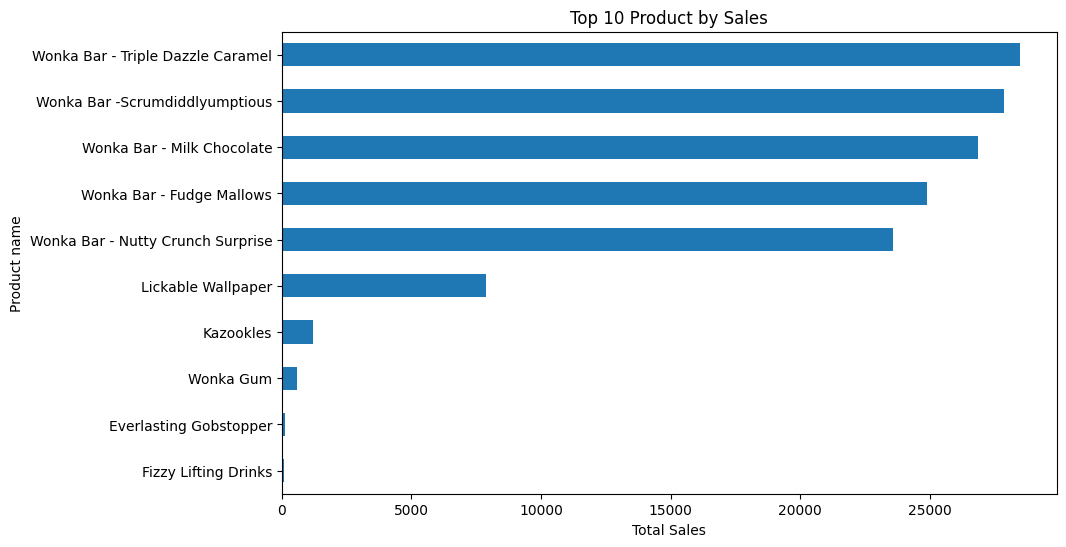

In [154]:
product_sales.head(10).sort_values().plot(
    kind = "barh",
    figsize = (10,6),
    title = "Top 10 Product by Sales"
)

plt.xlabel("Total Sales")
plt.ylabel("Product name")
plt.show()

### Gross Profit Analysis

In [155]:
product_profit = df.groupby("Product Name")["Gross Profit"].sum().sort_values(ascending = False)

product_profit.head(10)

Product Name
Wonka Bar -Scrumdiddlyumptious       19357.50
Wonka Bar - Triple Dazzle Caramel    18610.20
Wonka Bar - Milk Chocolate           17443.37
Wonka Bar - Nutty Crunch Surprise    16819.95
Wonka Bar - Fudge Mallows            16593.60
Lickable Wallpaper                    3930.00
Wonka Gum                              310.70
Everlasting Gobstopper                 104.00
Kazookles                               92.75
Hair Toffee                             59.50
Name: Gross Profit, dtype: float64

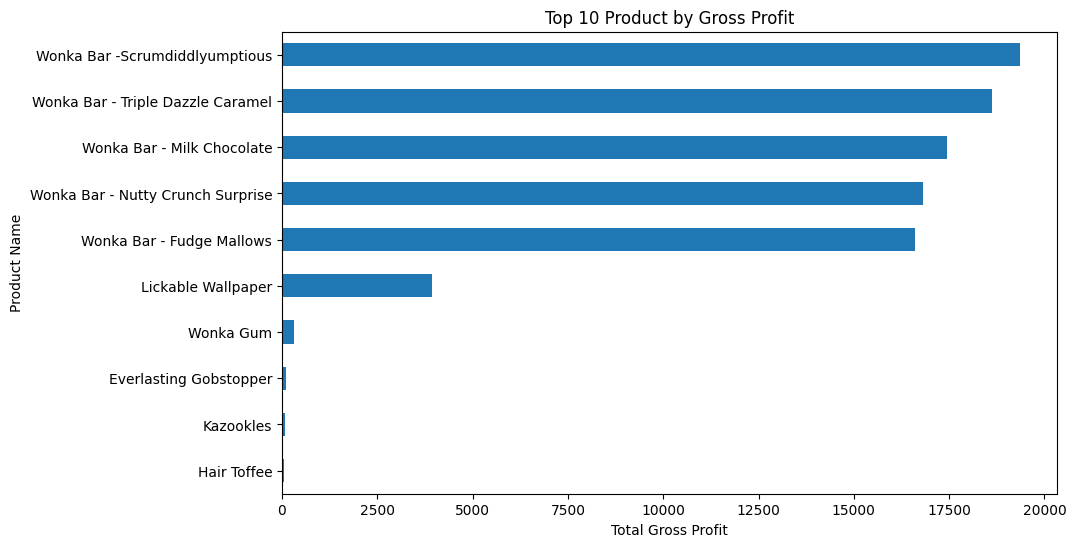

In [156]:
product_profit.head(10).sort_values().plot(
    kind = "barh",
    figsize = (10,6),
    title = "Top 10 Product by Gross Profit"
)

plt.xlabel("Total Gross Profit")
plt.ylabel("Product Name")
plt.show()

In [157]:
product_profit = df.groupby("Product Name")["Gross Profit"].sum().reset_index()

total_profit = df["Gross Profit"].sum()

product_profit["Profit Contribution (%)"] = (
    product_profit["Gross Profit"] / total_profit
) * 100

product_profit = product_profit.sort_values(
    "Profit Contribution (%)",
    ascending = False
)

product_profit.head(10)

,Product Name,Gross Profit,Profit Contribution (%)
13,Wonka Bar -Scrumdiddlyumptious,19357.50,20.715882
12,Wonka Bar - Triple Dazzle Caramel,18610.20,19.916141
10,Wonka Bar - Milk Chocolate,17443.37,18.667431
11,Wonka Bar - Nutty Crunch Surprise,16819.95,18.000263
9,Wonka Bar - Fudge Mallows,16593.60,17.758030
6,Lickable Wallpaper,3930.00,4.205782
14,Wonka Gum,310.70,0.332503
0,Everlasting Gobstopper,104.00,0.111298
4,Kazookles,92.75,0.099259
3,Hair Toffee,59.50,0.063675


### Profit Margin Analysis

In [158]:
product_margin = df.groupby("Product Name")["Profit Margin"].mean().sort_values(ascending = False)

product_margin.head(10)

Product Name
Everlasting Gobstopper               80.000000
Hair Toffee                          77.777778
Wonka Bar - Nutty Crunch Surprise    71.346705
Wonka Bar -Scrumdiddlyumptious       69.444444
Wonka Bar - Fudge Mallows            66.666667
Wonka Bar - Triple Dazzle Caramel    65.333333
Wonka Bar - Milk Chocolate           64.923077
Laffy Taffy                          62.311558
Fizzy Lifting Drinks                 60.000000
Wonka Gum                            52.000000
Name: Profit Margin, dtype: float64

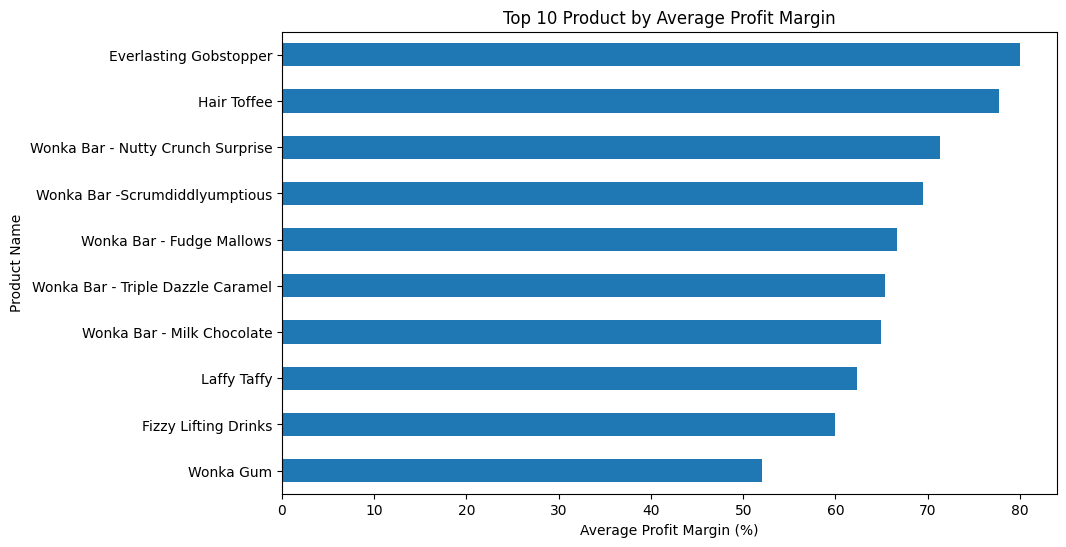

In [159]:
product_margin.head(10).sort_values().plot(
    kind = 'barh',
    figsize = (10,6),
    title = "Top 10 Product by Average Profit Margin"
)

plt.xlabel("Average Profit Margin (%)")
plt.ylabel("Product Name")
plt.show()

### Margin Risk Identification

Products with relatively lower profit margins may represent potential margin risk, especially when they also contribute significant sales or unit volume. In this analysis, products such as Wonka Gum, Fizzy Lifting Drinks, Laffy Taffy, and Milk Chocolate have lower profit margins compared with the highest-margin products.

However, lower margin alone does not mean that a product should be discontinued. These products should be evaluated together with their sales contribution, unit volume, and gross profit before making business decisions.

### Units Analysis

In [160]:
product_units = df.groupby("Product Name")["Units"].sum().sort_values(ascending = False)

product_units.head(10)

Product Name
Wonka Bar - Milk Chocolate           8267
Wonka Bar -Scrumdiddlyumptious       7743
Wonka Bar - Triple Dazzle Caramel    7596
Wonka Bar - Fudge Mallows            6914
Wonka Bar - Nutty Crunch Surprise    6755
Wonka Gum                             478
Lickable Wallpaper                    393
Kazookles                             371
SweeTARTS                              41
Laffy Taffy                            27
Name: Units, dtype: int64

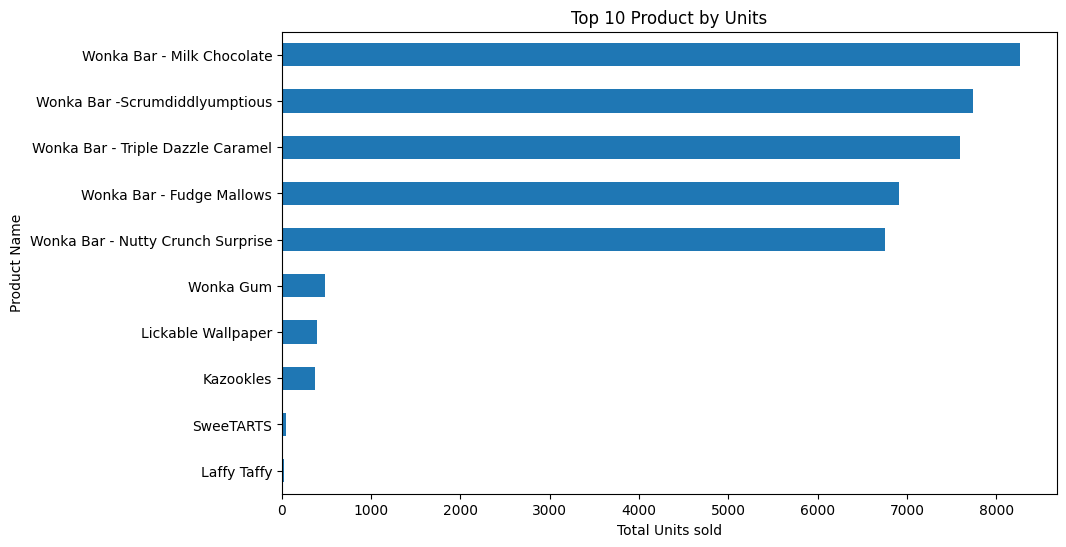

In [161]:
product_units.head(10).sort_values().plot(
    kind = "barh",
    figsize =(10,6),
    title = "Top 10 Product by Units"
)

plt.xlabel("Total Units sold")
plt.ylabel("Product Name")
plt.show()

Milk Chocolate sold the highest number of units, but Scrumdiddlyumptious generated higher sales and gross profit. This demonstrates why evaluating products only by sales volume or unit sales can give an incomplete view of profitability.

### Product - Level Profitability Classification

In [162]:
product_analysis = df.groupby("Product Name").agg(
    Sales = ("Sales", "sum"),
    Units = ("Units", "sum"),
    Gross_Profit = ("Gross Profit", "sum")
).reset_index()

product_analysis["Profit Margin (%)"] = (
    product_analysis["Gross_Profit"] /    
    product_analysis["Sales"]
) * 100

product_analysis["Profit per Unit"] = (
    product_analysis["Gross_Profit"] /    
    product_analysis["Sales"]
)

product_analysis

,Product Name,Sales,Units,Gross_Profit,Profit Margin (%),Profit per Unit
0,Everlasting Gobstopper,130.00,13,104.00,80.000000,0.800000
1,Fizzy Lifting Drinks,78.75,21,47.25,60.000000,0.600000
2,Fun Dip,12.00,8,4.80,40.000000,0.400000
3,Hair Toffee,76.50,17,59.50,77.777778,0.777778
4,Kazookles,1205.75,371,92.75,7.692308,0.076923
5,Laffy Taffy,53.73,27,33.48,62.311558,0.623116
6,Lickable Wallpaper,7860.00,393,3930.00,50.000000,0.500000
7,Nerds,15.00,10,7.00,46.666667,0.466667
8,SweeTARTS,61.50,41,28.70,46.666667,0.466667
9,Wonka Bar - Fudge Mallows,24890.40,6914,16593.60,66.666667,0.666667


In [163]:
product_by_profit = product_analysis.sort_values(
    "Gross_Profit",
    ascending=False
)

product_by_profit[
    ["Product Name", "Gross_Profit"]
]

,Product Name,Gross_Profit
13,Wonka Bar -Scrumdiddlyumptious,19357.50
12,Wonka Bar - Triple Dazzle Caramel,18610.20
10,Wonka Bar - Milk Chocolate,17443.37
11,Wonka Bar - Nutty Crunch Surprise,16819.95
9,Wonka Bar - Fudge Mallows,16593.60
6,Lickable Wallpaper,3930.00
14,Wonka Gum,310.70
0,Everlasting Gobstopper,104.00
4,Kazookles,92.75
3,Hair Toffee,59.50


In [164]:
product_by_margin = product_analysis.sort_values(
    "Profit Margin (%)",
    ascending=False
)

product_by_margin[
    ["Product Name", "Profit Margin (%)"]
]

,Product Name,Profit Margin (%)
0,Everlasting Gobstopper,80.000000
3,Hair Toffee,77.777778
11,Wonka Bar - Nutty Crunch Surprise,71.346705
13,Wonka Bar -Scrumdiddlyumptious,69.444444
9,Wonka Bar - Fudge Mallows,66.666667
12,Wonka Bar - Triple Dazzle Caramel,65.333333
10,Wonka Bar - Milk Chocolate,64.923077
5,Laffy Taffy,62.311558
1,Fizzy Lifting Drinks,60.000000
14,Wonka Gum,52.000000


In [165]:
profit_median = product_analysis["Gross_Profit"].median()
margin_median = product_analysis["Profit Margin (%)"].median()

high_profit_high_margin = product_analysis[
    (product_analysis["Gross_Profit"] >= profit_median) &
    (product_analysis["Profit Margin (%)"] >= margin_median)
]

high_profit_high_margin[
    ["Product Name", "Gross_Profit", "Profit Margin (%)"]
]

,Product Name,Gross_Profit,Profit Margin (%)
0,Everlasting Gobstopper,104.00,80.000000
9,Wonka Bar - Fudge Mallows,16593.60,66.666667
10,Wonka Bar - Milk Chocolate,17443.37,64.923077
11,Wonka Bar - Nutty Crunch Surprise,16819.95,71.346705
12,Wonka Bar - Triple Dazzle Caramel,18610.20,65.333333
13,Wonka Bar -Scrumdiddlyumptious,19357.50,69.444444


In [166]:
sales_median = product_analysis["Sales"].median()

high_sales_low_margin = product_analysis[
    (product_analysis["Sales"] >= sales_median) &
    (product_analysis["Profit Margin (%)"] < margin_median)
]

high_sales_low_margin[
    ["Product Name", "Sales", "Profit Margin (%)", "Gross_Profit"]
]

,Product Name,Sales,Profit Margin (%),Gross_Profit
4,Kazookles,1205.75,7.692308,92.75
6,Lickable Wallpaper,7860.00,50.000000,3930.00
14,Wonka Gum,597.50,52.000000,310.70


In [167]:
low_sales_low_profit = product_analysis[
    (product_analysis["Sales"] < sales_median) &
    (product_analysis["Profit Margin (%)"] < margin_median)
]

low_sales_low_profit[
    ["Product Name", "Sales", "Gross_Profit", "Profit Margin (%)"]
]

,Product Name,Sales,Gross_Profit,Profit Margin (%)
1,Fizzy Lifting Drinks,78.75,47.25,60.000000
2,Fun Dip,12.00,4.80,40.000000
7,Nerds,15.00,7.00,46.666667
8,SweeTARTS,61.50,28.70,46.666667


In [168]:
def classify_product(row):
    if row["Gross_Profit"] >= profit_median and row["Profit Margin (%)"] >= margin_median:
        return "High-Profit / High-Margin"

    elif row["Sales"] >= sales_median and row["Profit Margin (%)"] < margin_median:
        return "High-Sales / Low-Margin"

    elif row["Sales"] <sales_median and row["Gross_Profit"] < profit_median:
        return "Low-Sales / Low-Profit"

    else:
        return "Other"

product_analysis["Product Category"] = product_analysis.apply(
    classify_product,
    axis = 1
)            

product_analysis[
    [
        "Product Name",
        "Sales",
        "Gross_Profit",
        "Profit Margin (%)",
        "Product Category"
    ]
]

,Product Name,Sales,Gross_Profit,Profit Margin (%),Product Category
0,Everlasting Gobstopper,130.00,104.00,80.000000,High-Profit / High-Margin
1,Fizzy Lifting Drinks,78.75,47.25,60.000000,Low-Sales / Low-Profit
2,Fun Dip,12.00,4.80,40.000000,Low-Sales / Low-Profit
3,Hair Toffee,76.50,59.50,77.777778,Low-Sales / Low-Profit
4,Kazookles,1205.75,92.75,7.692308,High-Sales / Low-Margin
5,Laffy Taffy,53.73,33.48,62.311558,Low-Sales / Low-Profit
6,Lickable Wallpaper,7860.00,3930.00,50.000000,High-Sales / Low-Margin
7,Nerds,15.00,7.00,46.666667,Low-Sales / Low-Profit
8,SweeTARTS,61.50,28.70,46.666667,Low-Sales / Low-Profit
9,Wonka Bar - Fudge Mallows,24890.40,16593.60,66.666667,High-Profit / High-Margin


#### Product-Level Profitability Classification

Products were classified using median-based thresholds to identify different profitability patterns. Products with gross profit and profit margin at or above their respective median values were considered high-profit/high-margin products. Products with high sales but below-median profit margin were identified as high-sales/low-margin products. Products with below-median sales and gross profit were classified as low-sales/low-profit products.

This classification helps distinguish products that generate strong overall profitability from products that have high sales but relatively lower margins or products with limited sales and profit contribution.

In [169]:
product_profitability = df.groupby("Product Name").agg(
    Sales = ("Sales", "sum"),
    Units = ("Units", "sum"),
    Gross_Profit = ("Gross Profit", "sum")
).reset_index()

product_profitability["Profit Margin (%)"] = (
    product_profitability["Gross_Profit"] /   
    product_profitability["Sales"]
) * 100

product_profitability["Profit per Unit"] = (
    product_profitability["Gross_Profit"] /   
    product_profitability["Sales"]
)

total_profit = product_profitability["Gross_Profit"].sum()

product_profitability["Profit Contribution (%)"] = (
    product_profitability["Gross_Profit"] /   
    total_profit
) * 100

product_profitability = product_profitability.sort_values(
    "Gross_Profit",
    ascending = False
)

product_profitability

,Product Name,Sales,Units,Gross_Profit,Profit Margin (%),Profit per Unit,Profit Contribution (%)
13,Wonka Bar -Scrumdiddlyumptious,27874.80,7743,19357.50,69.444444,0.694444,20.715882
12,Wonka Bar - Triple Dazzle Caramel,28485.00,7596,18610.20,65.333333,0.653333,19.916141
10,Wonka Bar - Milk Chocolate,26867.75,8267,17443.37,64.923077,0.649231,18.667431
11,Wonka Bar - Nutty Crunch Surprise,23574.95,6755,16819.95,71.346705,0.713467,18.000263
9,Wonka Bar - Fudge Mallows,24890.40,6914,16593.60,66.666667,0.666667,17.758030
6,Lickable Wallpaper,7860.00,393,3930.00,50.000000,0.500000,4.205782
14,Wonka Gum,597.50,478,310.70,52.000000,0.520000,0.332503
0,Everlasting Gobstopper,130.00,13,104.00,80.000000,0.800000,0.111298
4,Kazookles,1205.75,371,92.75,7.692308,0.076923,0.099259
3,Hair Toffee,76.50,17,59.50,77.777778,0.777778,0.063675


### Profit Concentration (Pareto) Analysis

In [170]:
# Product-Level Sales
product_sales = df.groupby("Product Name")["Sales"].sum().reset_index()

# Sort by Sales from highest to lowest
product_sales = product_sales.sort_values("Sales", ascending = False)

# Calculate cumulative sales percentage
product_sales["Cumulative Sales (%)"] = (
    product_sales["Sales"].cumsum() / product_sales["Sales"].sum()
) * 100

product_sales

,Product Name,Sales,Cumulative Sales (%)
12,Wonka Bar - Triple Dazzle Caramel,28485.00,20.090472
13,Wonka Bar -Scrumdiddlyumptious,27874.80,39.750569
10,Wonka Bar - Milk Chocolate,26867.75,58.700394
9,Wonka Bar - Fudge Mallows,24890.40,76.255595
11,Wonka Bar - Nutty Crunch Surprise,23574.95,92.883008
6,Lickable Wallpaper,7860.00,98.426666
4,Kazookles,1205.75,99.277082
14,Wonka Gum,597.50,99.698498
0,Everlasting Gobstopper,130.00,99.790187
1,Fizzy Lifting Drinks,78.75,99.845730


In [171]:
revenue_80 = product_sales[
    product_sales["Cumulative Sales (%)"] <= 80
]

revenue_80

,Product Name,Sales,Cumulative Sales (%)
12,Wonka Bar - Triple Dazzle Caramel,28485.00,20.090472
13,Wonka Bar -Scrumdiddlyumptious,27874.80,39.750569
10,Wonka Bar - Milk Chocolate,26867.75,58.700394
9,Wonka Bar - Fudge Mallows,24890.40,76.255595


In [172]:
revenue_80 = product_sales[
    product_sales["Cumulative Sales (%)"] <= 80 
]

print("Products Contributing up to 80%  of revenue:", len(revenue_80))

Products Contributing up to 80%  of revenue: 4


In [173]:
product_sales[
    product_sales["Cumulative Sales (%)"] >= 80
].head(1)

,Product Name,Sales,Cumulative Sales (%)
11,Wonka Bar - Nutty Crunch Surprise,23574.95,92.883008


In [174]:
product_profit = df.groupby("Product Name")["Gross Profit"].sum().reset_index()

# Sort by Gross Profit
product_profit = product_profit.sort_values(
    "Gross Profit", ascending = False
)

# Calculate Cumulative Profit Percentage
product_profit["Cumulative Profit (%)"] = (
    product_profit["Gross Profit"].cumsum() /    
    product_profit["Gross Profit"].sum()
) * 100

product_profit

,Product Name,Gross Profit,Cumulative Profit (%)
13,Wonka Bar -Scrumdiddlyumptious,19357.50,20.715882
12,Wonka Bar - Triple Dazzle Caramel,18610.20,40.632023
10,Wonka Bar - Milk Chocolate,17443.37,59.299454
11,Wonka Bar - Nutty Crunch Surprise,16819.95,77.299717
9,Wonka Bar - Fudge Mallows,16593.60,95.057747
6,Lickable Wallpaper,3930.00,99.263528
14,Wonka Gum,310.70,99.596031
0,Everlasting Gobstopper,104.00,99.707329
4,Kazookles,92.75,99.806588
3,Hair Toffee,59.50,99.870263


In [175]:
profit_80 = product_profit[
    product_profit["Cumulative Profit (%)"] <= 80
]

print("Product Contributing up to 80%  of Profit:", len(profit_80))

Product Contributing up to 80%  of Profit: 4


In [176]:
product_profit[
    product_profit["Cumulative Profit (%)"] >= 80
].head(1)

,Product Name,Gross Profit,Cumulative Profit (%)
9,Wonka Bar - Fudge Mallows,16593.6,95.057747


#### Profit Concentration (Pareto) Insights

The product-level analysis shows that sales and gross profit are concentrated among a small number of products. The top five products contribute approximately 92.9% of total sales and 95.06% of total gross profit.

This concentration indicates a potential over-dependency risk because a decline in demand or profitability for these major products could significantly affect overall business performance.

The business should monitor the performance of its major contributing products while exploring opportunities to improve the contribution of other products. This may help reduce dependency on a limited product range.

The state-level analysis also shows geographic concentration, with California accounting for 19.72% of total orders, followed by New York and Texas. These states represent important markets that should be monitored for changes in demand and operational performance.

The dataset does not contain direct measures of delivery congestion or warehouse capacity, so high order volume indicates geographic concentration rather than confirmed congestion.

### Cost Structure Diagnostics

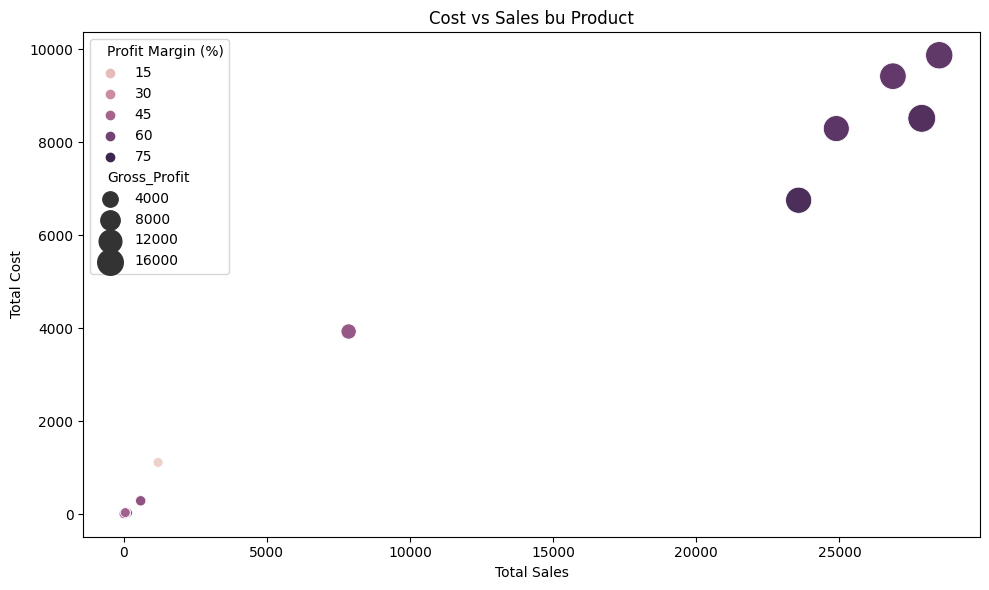

In [177]:
# Calculate total Sales and Cost for each Products
cost_sales = df.groupby("Product Name").agg(
    Sales = ("Sales", "sum"),
    Cost = ("Cost", "sum"),
    Gross_Profit = ("Gross Profit", "sum")
).reset_index()

# Calculate Profit Margin
cost_sales["Profit Margin (%)"] = (
    cost_sales["Gross_Profit"] / cost_sales["Sales"]
) * 100

# Create Scatter plot
plt.figure(figsize = (10,6))

sns.scatterplot(
    data = cost_sales,
    x = "Sales",
    y = "Cost",
    hue = "Profit Margin (%)",
    size = "Gross_Profit",
    sizes = (50, 400)
)

plt.title("Cost vs Sales bu Product")
plt.xlabel("Total Sales")
plt.ylabel("Total Cost")
plt.tight_layout()
plt.show()

In [178]:
# Use median values as comparison thresholds
median_cost = cost_sales["Cost"].median()
median_margin = cost_sales["Profit Margin (%)"].median()

cost_heavy_margin_poor = cost_sales[
    (cost_sales["Cost"] >= median_cost) &
    (cost_sales["Profit Margin (%)"] < median_margin)
].sort_values("Cost", ascending = False)

cost_heavy_margin_poor[
    ["Product Name", "Sales", "Cost",
    "Gross_Profit", "Profit Margin (%)"]
]

,Product Name,Sales,Cost,Gross_Profit,Profit Margin (%)
6,Lickable Wallpaper,7860.00,3930.0,3930.00,50.000000
4,Kazookles,1205.75,1113.0,92.75,7.692308
14,Wonka Gum,597.50,286.8,310.70,52.000000


#### Cost-Heavy and Margin-Poor Product Insights

The cost structure analysis identified Lickable Wallpaper, Kazookles, and Wonka Gum as products with above-median costs and below-median profit margins.

Kazookles requires particular attention because it records a low profit margin of 7.69%, with total cost of 1,113.00 against sales of 1,205.75. This indicates a relatively small gross profit contribution compared with its sales.

Lickable Wallpaper has a profit margin of 50.00% and generates gross profit of 3,930.00. Its pricing and cost structure may be reviewed to identify opportunities for improving profitability. Wonka Gum has a profit margin of 52.00%, but its overall sales and gross profit are comparatively low.

These findings identify products for further investigation. Pricing changes, supplier cost renegotiation, or discontinuation should not be decided from profit margin alone; sales contribution, total gross profit, demand, and business importance should also be considered.


In [179]:
median_sales = cost_sales["Sales"].median()
median_profit = cost_sales["Gross_Profit"].median()

def review_product(row):
    if (
        row["Cost"] >= median_cost and
        row["Profit Margin (%)"] < median_margin
    ):
        return "Cost Renegotiation Review" 
    elif (
        row["Sales"] >= median_sales and
        row["Profit Margin (%)"] < margin_median
    ):
        return "Pricing Review"
    elif (
        row["Sales"] < median_sales and
        row["Gross_Profit"] < median_profit
    ):
        return "Discontinuation Review"
    else:
        return "No Immediate Flag"

cost_sales["Review Recommendation"] = cost_sales.apply(
    review_product, axis = 1
)                    

cost_sales.sort_values(
    "Profit Margin (%)", ascending = True 
)

,Product Name,Sales,Cost,Gross_Profit,Profit Margin (%),Review Recommendation
4,Kazookles,1205.75,1113.00,92.75,7.692308,Cost Renegotiation Review
2,Fun Dip,12.00,7.20,4.80,40.000000,Discontinuation Review
7,Nerds,15.00,8.00,7.00,46.666667,Discontinuation Review
8,SweeTARTS,61.50,32.80,28.70,46.666667,Discontinuation Review
6,Lickable Wallpaper,7860.00,3930.00,3930.00,50.000000,Cost Renegotiation Review
14,Wonka Gum,597.50,286.80,310.70,52.000000,Cost Renegotiation Review
1,Fizzy Lifting Drinks,78.75,31.50,47.25,60.000000,Discontinuation Review
5,Laffy Taffy,53.73,20.25,33.48,62.311558,Discontinuation Review
10,Wonka Bar - Milk Chocolate,26867.75,9424.38,17443.37,64.923077,No Immediate Flag
12,Wonka Bar - Triple Dazzle Caramel,28485.00,9874.80,18610.20,65.333333,No Immediate Flag


#### Cost Structure Diagnostic Insights

The cost structure analysis classified products into preliminary review categories based on their sales, total cost, gross profit, and profit margin.

Kazookles was identified for cost renegotiation review because it has a low profit margin of 7.69% and generates gross profit of only 92.75. Lickable Wallpaper and Wonka Gum were also flagged for cost review because their costs and margins meet the selected thresholds.

Wonka Bar - Milk Chocolate and Wonka Bar - Triple Dazzle Caramel were flagged for pricing review because they have high sales but relatively lower profit margins than the median threshold used in the analysis.

Several products, including Fun Dip, Nerds, SweeTARTS, Fizzy Lifting Drinks, Laffy Taffy, and Hair Toffee, were flagged for discontinuation review because of their relatively low sales and gross profit. These products require further evaluation before any discontinuation decision is made.

Overall, the analysis provides a starting point for identifying potential cost-control and pricing opportunities. The recommendations are preliminary because the dataset does not include supplier agreements, competitor prices, demand forecasts, or product-specific strategic importance.


In [180]:
# Summarize the number of products in each review category
review_summary = cost_sales.groupby(
    "Review Recommendation"
).agg(
    Number_of_Products=("Product Name", "count"),
    Total_Sales=("Sales", "sum"),
    Total_Cost=("Cost", "sum"),
    Total_Gross_Profit=("Gross_Profit", "sum")
).reset_index()

review_summary

,Review Recommendation,Number_of_Products,Total_Sales,Total_Cost,Total_Gross_Profit
0,Cost Renegotiation Review,3,9663.25,5329.80,4333.45
1,Discontinuation Review,6,297.48,116.75,180.73
2,No Immediate Flag,6,131822.90,42894.28,88928.62


In [181]:
review_summary["Sales Contribution (%)"] = (
    review_summary["Total_Sales"] / cost_sales["Sales"].sum()
) * 100

review_summary["Profit Contribution (%)"] = (
    review_summary["Total_Gross_Profit"] / cost_sales["Gross_Profit"].sum()
) * 100

review_summary

,Review Recommendation,Number_of_Products,Total_Sales,Total_Cost,Total_Gross_Profit,Sales Contribution (%),Profit Contribution (%)
0,Cost Renegotiation Review,3,9663.25,5329.80,4333.45,6.815491,4.637543
1,Discontinuation Review,6,297.48,116.75,180.73,0.209813,0.193412
2,No Immediate Flag,6,131822.90,42894.28,88928.62,92.974697,95.169045


#### Product Review Category Contribution Analysis

The product review summary shows that the four products classified as No Immediate Flag contribute 53.93% of total sales and 56.59% of total gross profit, making them important contributors to business performance.

The two products flagged for Pricing Review account for 39.04% of sales and 38.58% of gross profit. Their pricing and cost structures may be examined to identify opportunities for improving profit margins without negatively affecting demand.

The three products classified for Cost Renegotiation Review contribute 6.82% of sales and 4.64% of gross profit. These products may require further investigation into their cost structures and potential cost-control opportunities.

The six products flagged for Discontinuation Review contribute only 0.21% of sales and 0.19% of gross profit. Their relatively small contribution makes them candidates for further evaluation, but decisions should also consider demand, strategic importance, and other business factors.

Overall, this analysis helps prioritize products for financial review based on their contribution to sales and gross profit. The categories provide preliminary guidance rather than automatic business decisions.


## 10. Division Analysis

### 10.1 Aggregate Metrics by Division

In [182]:
division_analysis = df.groupby("Division").agg({
    "Sales" : "sum",
    "Units" : "sum",
    "Gross Profit" : "sum"
}).sort_values("Gross Profit", ascending = False)

division_analysis

,Sales,Units,Gross Profit
Division,,,
Chocolate,131692.90,37275,88824.62
Other,9663.25,1242,4333.45
Sugar,427.48,137,284.73


### Sales Analysis

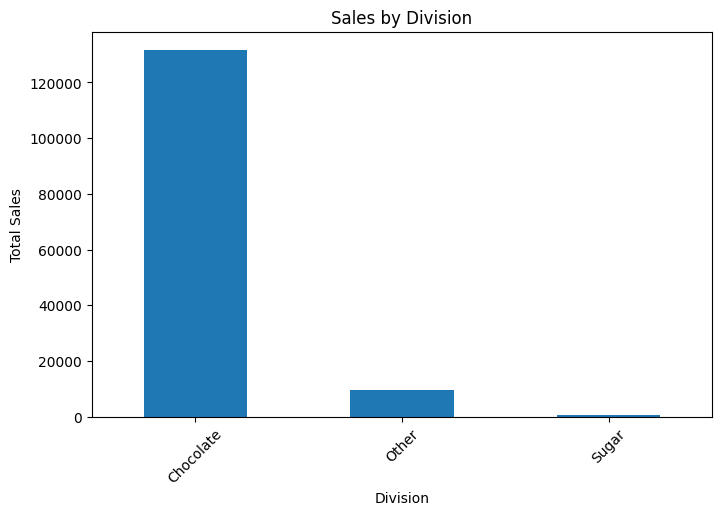

In [183]:
division_analysis['Sales'].plot(
    kind = 'bar',
    figsize = (8,5),
    title = "Sales by Division"
)

plt.xlabel("Division")
plt.ylabel("Total Sales")
plt.xticks(rotation = 45)
plt.show()

### Gross Profit Analysis

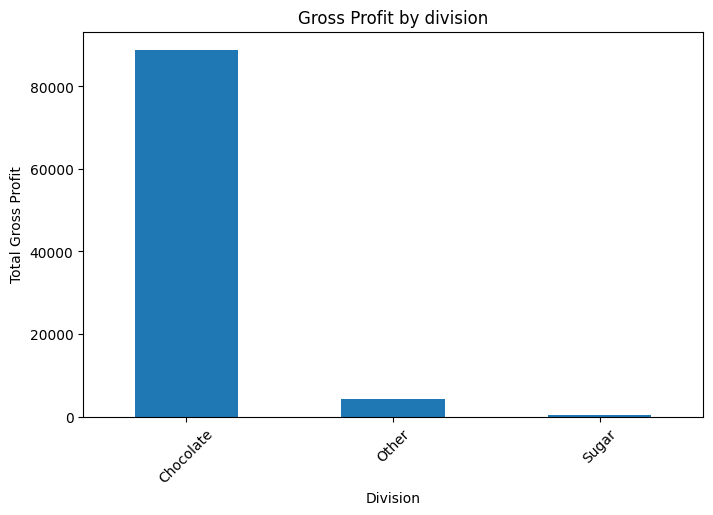

In [184]:
division_analysis['Gross Profit'].plot(
    kind = "bar",
    figsize = (8,5),
    title = "Gross Profit by division"
)

plt.xlabel("Division")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation = 45)
plt.show()

In [185]:
division_analysis[["Sales", "Gross Profit"]]

,Sales,Gross Profit
Division,,
Chocolate,131692.90,88824.62
Other,9663.25,4333.45
Sugar,427.48,284.73


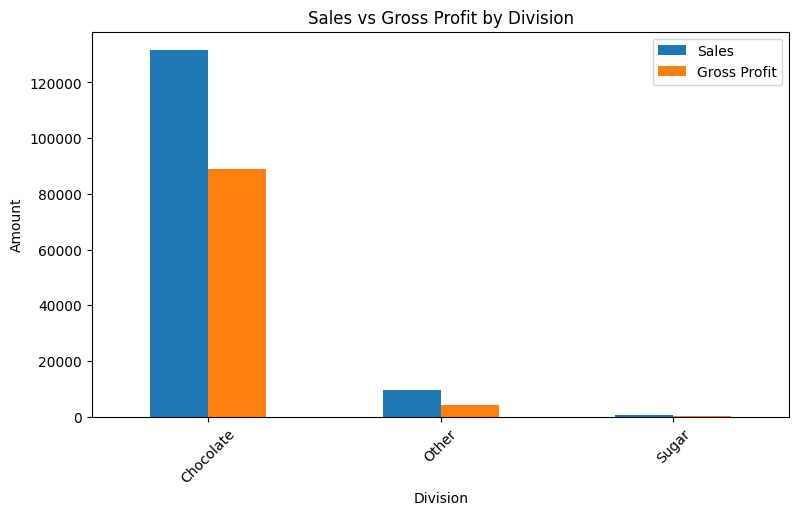

In [186]:
division_analysis[["Sales","Gross Profit"]].plot(
    kind = "bar",
    figsize = (9,5),
    title = "Sales vs Gross Profit by Division"
)

plt.xlabel("Division")
plt.ylabel("Amount")
plt.xticks(rotation = 45)
plt.legend()
plt.show()

### Profit Margin Analysis

In [187]:
division_margin = df.groupby("Division")["Profit Margin"].mean().sort_values(ascending = False)

division_margin

Division
Chocolate    67.458162
Sugar        57.689001
Other        37.672457
Name: Profit Margin, dtype: float64

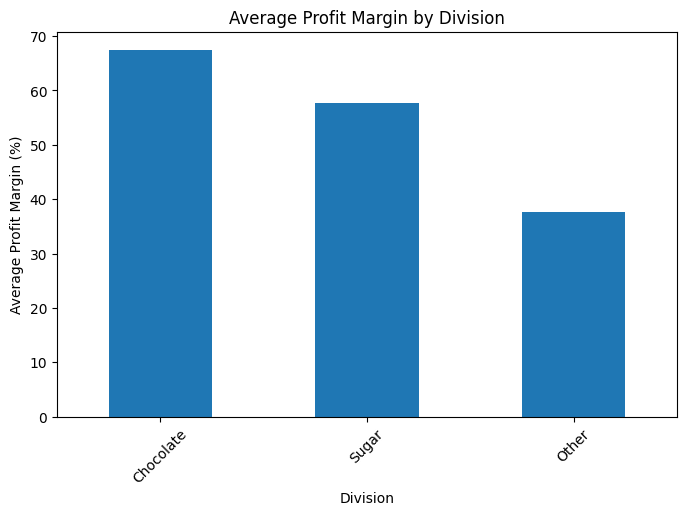

In [188]:
division_margin.plot(
    kind = "bar",
    figsize = (8,5),
    title = "Average Profit Margin by Division"
)

plt.xlabel("Division")
plt.ylabel("Average Profit Margin (%)")
plt.xticks(rotation = 45)
plt.show()

In [189]:
division_analysis = df.groupby("Division").agg(
    Sales=("Sales", "sum"),
    Units=("Units", "sum"),
    Gross_Profit=("Gross Profit", "sum")
).reset_index()

In [190]:
division_analysis["Profit Margin (%)"] = (
    division_analysis["Gross_Profit"] /
    division_analysis["Sales"]
) * 100

### 10.2 Revenue vs Profit Contribution

In [191]:
division_analysis["Sales Contribution (%)"] = (
    division_analysis["Sales"] / df["Sales"].sum()
) * 100

division_analysis["Profit Contribution (%)"] = (
    division_analysis["Gross_Profit"] / df["Gross Profit"].sum()
) * 100

division_analysis["Revenue-Profit Gap (%)"] = (
    division_analysis["Profit Contribution (%)"] - 
    division_analysis["Sales Contribution (%)"]
)

division_analysis

,Division,Sales,Units,Gross_Profit,Profit Margin (%),Sales Contribution (%),Profit Contribution (%),Revenue-Profit Gap (%)
0,Chocolate,131692.90,37275,88824.62,67.448298,92.883008,95.057747,2.174739
1,Other,9663.25,1242,4333.45,44.844643,6.815491,4.637543,-2.177948
2,Sugar,427.48,137,284.73,66.606625,0.301502,0.304710,0.003209


### 10.3 Financial Efficiency

In [192]:
margin_median = division_analysis["Profit Margin (%)"].median()

strong_efficiency = division_analysis[
    division_analysis["Profit Margin (%)"] >= margin_median
]

strong_efficiency[
    ["Division", "Sales", "Gross_Profit", "Profit Margin (%)"]
]

,Division,Sales,Gross_Profit,Profit Margin (%)
0,Chocolate,131692.90,88824.62,67.448298
2,Sugar,427.48,284.73,66.606625


### 10.4 Margin Issues

In [193]:
structural_margin_issues = division_analysis[
    division_analysis["Profit Margin (%)"] < margin_median
]

structural_margin_issues[
    ["Division", "Sales", "Gross_Profit", "Profit Margin (%)"]
]

,Division,Sales,Gross_Profit,Profit Margin (%)
1,Other,9663.25,4333.45,44.844643


### Division-Level Performance Insights

The Chocolate division is the strongest financial performer, generating the highest sales, gross profit, and profit margin of 67.45%. Its share of gross profit is higher than its share of sales, indicating strong profitability relative to its revenue contribution.

The Other division has the lowest profit margin at 44.84% and contributes a smaller share of total gross profit compared with its sales contribution. Therefore, it may represent a potential margin issue that requires further investigation.

The Sugar division has a profit margin of 66.61%, which is relatively high, but its overall contribution to sales and gross profit is very small.

## 11. Region Analysis

In [194]:
region_analysis = df.groupby("Region").agg({
    "Sales": "sum",
    "Units": "sum",
    "Gross Profit": "sum"
}).sort_values("Gross Profit", ascending = False)

region_analysis

,Sales,Units,Gross Profit
Region,,,
Pacific,46301.53,12466,30485.94
Atlantic,41197.24,11159,26973.70
Interior,32037.60,8820,21282.49
Gulf,22247.26,6209,14700.67


### Sales Analysis

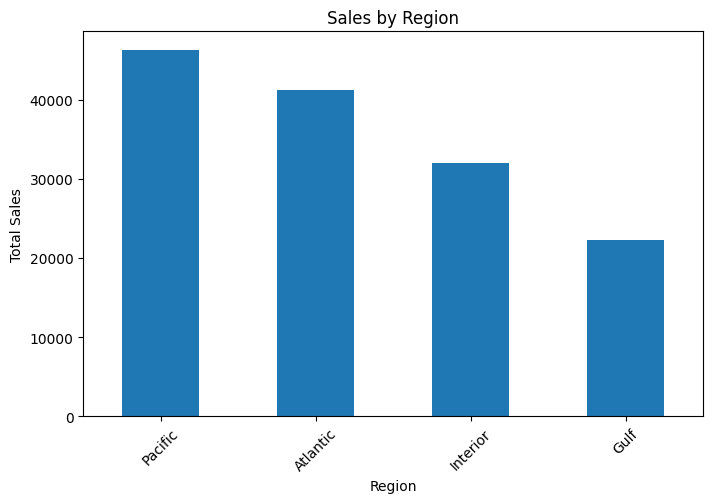

In [195]:
region_analysis["Sales"].plot(
    kind = "bar",
    figsize = (8,5),
    title = "Sales by Region"
)

plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.xticks(rotation = 45)
plt.show()

### Profit Margin Analysis

In [196]:
region_margin = df.groupby("Region")["Profit Margin"].mean().sort_values(ascending = False)

region_margin

Region
Interior    66.873913
Pacific     66.586450
Gulf        66.418919
Atlantic    66.205364
Name: Profit Margin, dtype: float64

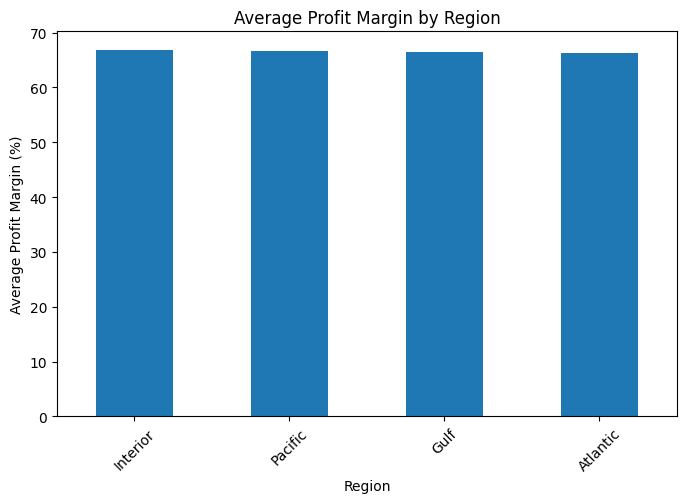

In [197]:
region_margin.plot(
    kind = "bar",
    figsize = (8,5),
    title = "Average Profit Margin by Region"
)

plt.xlabel("Region")
plt.ylabel("Average Profit Margin (%)")
plt.xticks(rotation = 45)
plt.show()

In [198]:
region_analysis[["Sales", "Gross Profit"]]

,Sales,Gross Profit
Region,,
Pacific,46301.53,30485.94
Atlantic,41197.24,26973.70
Interior,32037.60,21282.49
Gulf,22247.26,14700.67


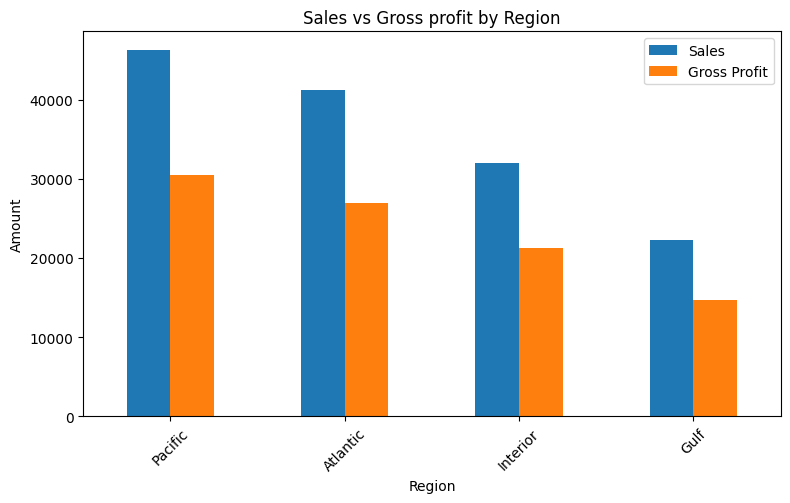

In [199]:
region_analysis[["Sales","Gross Profit"]].plot(
    kind = "bar",
    figsize = (9,5),
    title = "Sales vs Gross profit by Region"
)

plt.xlabel("Region")
plt.ylabel("Amount")
plt.xticks(rotation =45)
plt.legend()
plt.show()

### State-Level Order Concentration

In [200]:
state_analysis = df.groupby("State/Province").agg(
    Orders = ("Order ID", "nunique"),
    Sales = ("Sales", "sum"),
    Units = ("Units", "sum"),
    Gross_Profit = ("Gross Profit", "sum")
)

state_analysis = state_analysis.sort_values(
    "Orders", ascending = False
)

state_analysis.head(10)

,Orders,Sales,Units,Gross_Profit
State/Province,,,,
California,1686,27917.40,7667,18479.42
New York,942,15541.03,4224,10222.44
Texas,833,13416.09,3724,8909.53
Pennsylvania,487,8027.03,2153,5225.47
Illinois,433,6898.96,1845,4557.68
Washington,432,6921.15,1883,4566.64
Ohio,392,6768.95,1759,4413.03
Florida,319,4804.02,1379,3207.11
North Carolina,216,3450.86,983,2331.16


## State-Level Order Concentration

The state-level analysis shows that California has the highest order concentration with 1,686 orders, followed by New York with 942 orders and Texas with 833 orders. California also records the highest sales, units sold, and gross profit among the states shown.

The concentration of orders and business activity in a small number of states indicates a degree of geographic dependency. California, New York, and Texas are particularly important markets and should be monitored closely because changes in demand or operational performance in these states could have a noticeable impact on overall business performance.

However, the available dataset does not contain direct measures of transportation congestion, warehouse capacity, or delivery delays. Therefore, high order volume is treated as an indicator of geographic concentration rather than direct evidence of congestion.

In [201]:
state_analysis["Order Contribution (%)"] = (
    state_analysis["Orders"] / df["Order ID"].nunique()
) * 100

state_analysis.head(10)

,Orders,Sales,Units,Gross_Profit,Order Contribution (%)
State/Province,,,,,
California,1686,27917.40,7667,18479.42,19.721605
New York,942,15541.03,4224,10222.44,11.018833
Texas,833,13416.09,3724,8909.53,9.743830
Pennsylvania,487,8027.03,2153,5225.47,5.696573
Illinois,433,6898.96,1845,4557.68,5.064920
Washington,432,6921.15,1883,4566.64,5.053223
Ohio,392,6768.95,1759,4413.03,4.585332
Florida,319,4804.02,1379,3207.11,3.731431
North Carolina,216,3450.86,983,2331.16,2.526611


In [202]:
state_analysis = state_analysis.reset_index()

state_analysis[
    ["State/Province", "Orders", "Order Contribution (%)", "Sales", "Gross_Profit"]
].head(10)

,State/Province,Orders,Order Contribution (%),Sales,Gross_Profit
0,California,1686,19.721605,27917.40,18479.42
1,New York,942,11.018833,15541.03,10222.44
2,Texas,833,9.743830,13416.09,8909.53
3,Pennsylvania,487,5.696573,8027.03,5225.47
4,Illinois,433,5.064920,6898.96,4557.68
5,Washington,432,5.053223,6921.15,4566.64
6,Ohio,392,4.585332,6768.95,4413.03
7,Florida,319,3.731431,4804.02,3207.11
8,North Carolina,216,2.526611,3450.86,2331.16
9,Michigan,209,2.444730,3331.00,2236.21


#### Geographic Dependency and Concentration

California is the most important state by order concentration, accounting for 19.72% of total orders. New York and Texas follow with 11.02% and 9.74%, respectively.

The high order contribution of these states indicates that business activity is concentrated in a relatively small number of geographic markets. California is particularly important because it also records the highest sales and gross profit among the states analyzed.

This concentration creates a potential geographic dependency risk. A significant decline in demand or operational performance in major states could affect overall sales and profitability.

However, high order concentration should not be interpreted as direct evidence of congestion because the dataset does not contain transportation congestion, warehouse capacity, or delivery-delay information.

## 12. Time Analysis

In [203]:
year_analysis = df.groupby("Year").agg({
    "Sales": "sum",
    "Units": "sum",
    "Gross Profit": "sum"
})

year_analysis

,Sales,Units,Gross Profit
Year,,,
2024,57956.20,15899,38151.43
2025,83827.43,22755,55291.37


### Yearly Sales Analysis

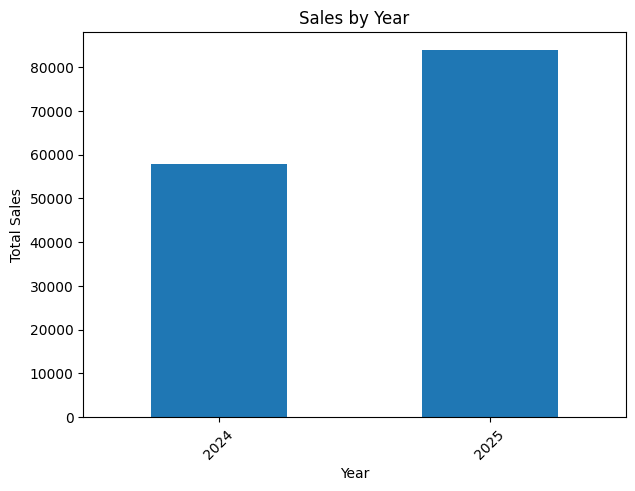

In [204]:
year_analysis["Sales"].plot(
    kind = "bar",
    figsize = (7,5),
    title = "Sales by Year"
)

plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(rotation = 45)
plt.show()

### Yearly Gross Profit Analysis

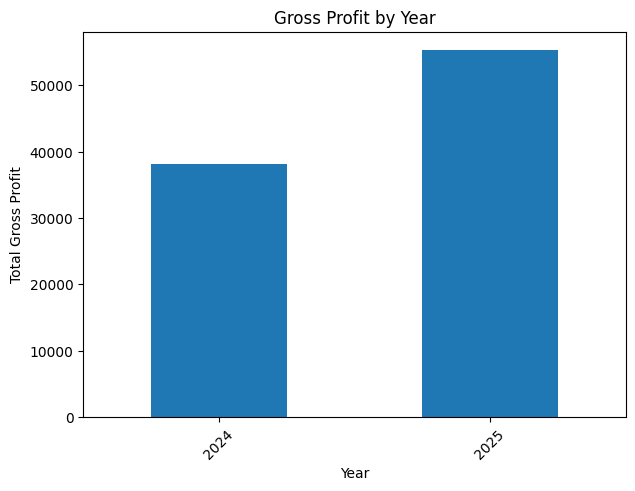

In [205]:
year_analysis["Gross Profit"].plot(
    kind = "bar",
    figsize = (7,5),
    title = "Gross Profit by Year"
)

plt.xlabel("Year")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation = 45)
plt.show()

### Monthly Sales Analysis

In [206]:
monthly_sales = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Sales"].sum()

monthly_sales.head()

Order Date
2024-01    2093.90
2024-02    1379.87
2024-03    4138.90
2024-04    3988.22
2024-05    3951.52
Freq: M, Name: Sales, dtype: float64

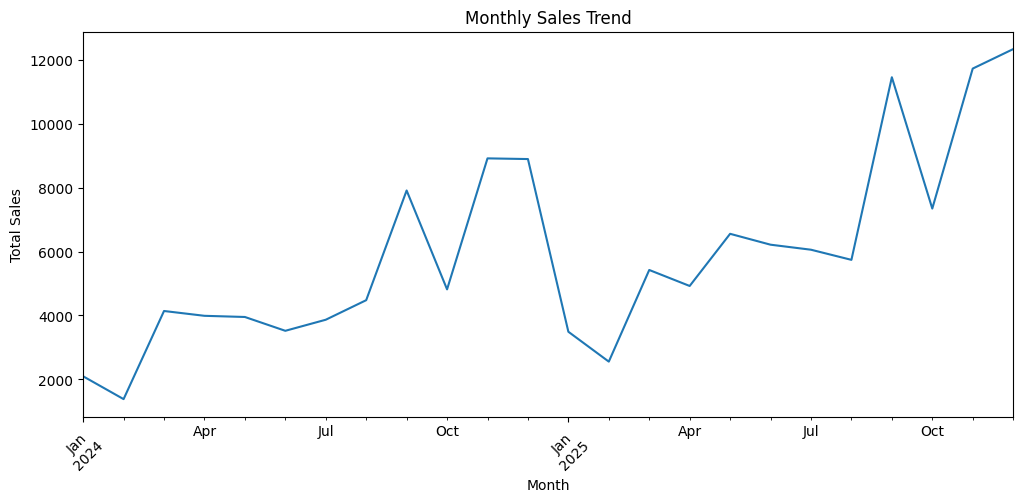

In [207]:
monthly_sales.plot(
    kind = "line",
    figsize = (12,5),
    title = "Monthly Sales Trend"
)

plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation =45)
plt.show()

### Monthly Gross Profit Analysis

In [208]:
monthly_profit = df.groupby(
    df["Order Date"].dt.to_period("M")
)["Gross Profit"].sum()

monthly_profit.head()

Order Date
2024-01    1366.14
2024-02     908.59
2024-03    2671.16
2024-04    2612.81
2024-05    2615.44
Freq: M, Name: Gross Profit, dtype: float64

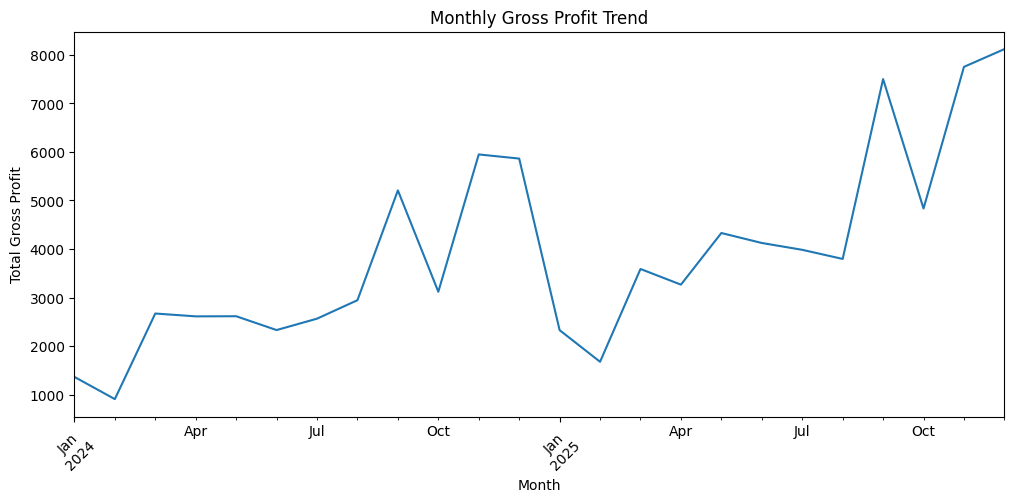

In [209]:
monthly_profit.plot(
    kind = "line",
    figsize = (12,5),
    title = "Monthly Gross Profit Trend"
)

plt.xlabel("Month")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation =45)
plt.show()

### Yearly Profit Margin Analysis

In [210]:
year_margin = df.groupby("Year")["Profit Margin"].mean()

year_margin

Year
2024    66.389104
2025    66.600919
Name: Profit Margin, dtype: float64

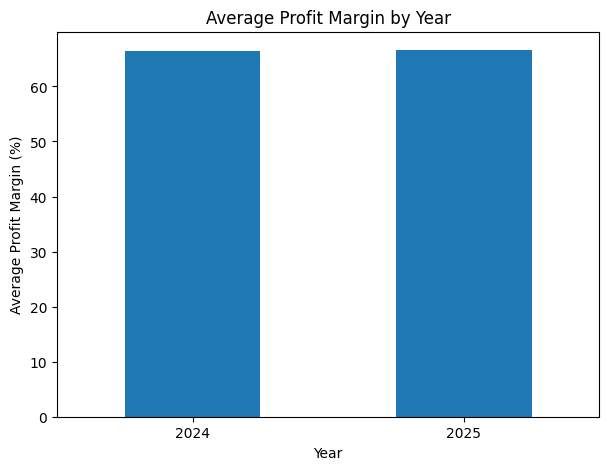

In [211]:
year_margin.plot(
    kind = "bar",
    figsize = (7,5),
    title = "Average Profit Margin by Year"
)

plt.xlabel("Year")
plt.ylabel("Average Profit Margin (%)")
plt.xticks(rotation = 0)
plt.show()

## 13. Machine Learning

In [212]:
df["Profit Margin"].describe()

count    10194.000000
mean        66.514045
std          6.721012
min          7.692308
25%         65.333333
50%         66.666667
75%         69.444444
max         80.000000
Name: Profit Margin, dtype: float64

### 13.1 Target Creation

In [213]:
df["Profitability Category"] = pd.qcut(
    df["Profit Margin"],
    q = 3,
    labels = ["Low", "Medium", "High"]
)

df["Profitability Category"].value_counts()

Profitability Category
Medium    4824
Low       3547
High      1823
Name: count, dtype: int64

Profitability categories were created using qcut, which divides observations into three groups based on the distribution of Profit Margin. Therefore, the Low, Medium, and High categories are relative categories based on this dataset rather than predefined business thresholds.

In [214]:
print("Number of Unique Products:",df["Product Name"].nunique())

Number of Unique Products: 15


In [215]:
print(df["Product Name"].value_counts().head(10))

Product Name
Wonka Bar - Milk Chocolate           2137
Wonka Bar -Scrumdiddlyumptious       2064
Wonka Bar - Triple Dazzle Caramel    2015
Wonka Bar - Fudge Mallows            1818
Wonka Bar - Nutty Crunch Surprise    1810
Wonka Gum                             120
Kazookles                              96
Lickable Wallpaper                     94
Laffy Taffy                            10
SweeTARTS                              10
Name: count, dtype: int64


In [216]:
product_category = pd.crosstab(
    df["Product Name"],
    df["Profitability Category"],
    normalize = "index",
) * 100

print(product_category.round(2))

Profitability Category                Low  Medium    High
Product Name                                             
Everlasting Gobstopper               0.00    0.00  100.00
Fizzy Lifting Drinks               100.00    0.00    0.00
Fun Dip                            100.00    0.00    0.00
Hair Toffee                          0.00    0.00  100.00
Kazookles                          100.00    0.00    0.00
Laffy Taffy                        100.00    0.00    0.00
Lickable Wallpaper                 100.00    0.00    0.00
Nerds                              100.00    0.00    0.00
SweeTARTS                          100.00    0.00    0.00
Wonka Bar - Fudge Mallows            0.00  100.00    0.00
Wonka Bar - Milk Chocolate         100.00    0.00    0.00
Wonka Bar - Nutty Crunch Surprise    0.00    0.00  100.00
Wonka Bar - Triple Dazzle Caramel   52.95   47.05    0.00
Wonka Bar -Scrumdiddlyumptious       0.00   99.71    0.29
Wonka Gum                          100.00    0.00    0.00


### 13.2 Feature Selection

In [217]:
x = df[
    [
        "Units",
        "Division",
        "Region",
        "Ship Mode",
        "Country/Region",
        "Product Name",
        "Year",
        "Month",
        "Quarter"
    ]
]

y = df["Profitability Category"]

print("X Shape: ",x.shape)
print("Y Shape: ",y.shape)

X Shape:  (10194, 9)
Y Shape:  (10194,)


### 13.3 Train-Test Split

In [218]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

print("x_train: ",x_train.shape)
print("x_test: ",x_test.shape)
print("y_train: ",y_train.shape)
print("y_test: ",y_test.shape)

x_train:  (8155, 9)
x_test:  (2039, 9)
y_train:  (8155,)
y_test:  (2039,)


### 13.4 Data Preprocessing

In [219]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "Division",
    "Region",
    "Ship Mode",
    "Country/Region",
    "Product Name",
    "Month"
]

preprocessor = ColumnTransformer(
    transformers = [
        ("cat", OneHotEncoder(handle_unknown = "ignore"), categorical_features)
    ],
    remainder = "passthrough"
)

### 13.5 Logistic Regression

In [220]:
from sklearn.linear_model import LogisticRegression

In [221]:
logistic_model = LogisticRegression(
    max_iter = 1000,
    random_state = 42
)

In [222]:
from sklearn.pipeline import Pipeline

In [223]:
logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", logistic_model)
])

In [224]:
x_train["Month"] = x_train["Month"].astype(str)
x_test["Month"] = x_test["Month"].astype(str)

C:\Users\Sumit\AppData\Local\Temp\ipykernel_13680\694042863.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x_train["Month"] = x_train["Month"].astype(str)
C:\Users\Sumit\AppData\Local\Temp\ipykernel_13680\694042863.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x_test["Month"] = x_test["Month"].astype(str)


In [225]:
logistic_pipeline.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Division', 'Region',
                                                   'Ship Mode',
                                                   'Country/Region',
                                                   'Product Name',
                                                   'Month'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [226]:
y_pred = logistic_pipeline.predict(x_test)

print(y_pred[:20])

['Low' 'Low' 'Low' 'High' 'Low' 'Low' 'Low' 'Medium' 'Medium' 'Low' 'High'
 'High' 'Medium' 'Medium' 'High' 'Low' 'Medium' 'Medium' 'Medium' 'Low']


In [227]:
from sklearn.metrics import accuracy_score, classification_report


accuracy = accuracy_score(y_test, y_pred)

print("Accuracy: ",accuracy)

print("\nClassification Report: ")
print(classification_report(y_test, y_pred))

Accuracy:  0.9318293281020108

Classification Report: 
              precision    recall  f1-score   support

        High       1.00      0.99      1.00       365
         Low       0.92      0.88      0.90       709
      Medium       0.92      0.95      0.93       965

    accuracy                           0.93      2039
   macro avg       0.94      0.94      0.94      2039
weighted avg       0.93      0.93      0.93      2039



In [228]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[362   2   1]
 [  0 626  83]
 [  0  53 912]]


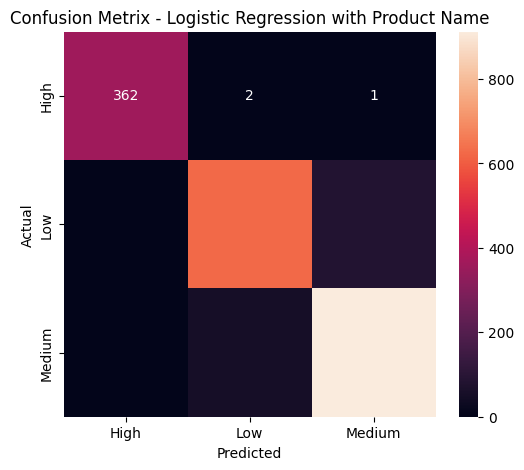

In [229]:
plt.figure(figsize = (6,5))

sns.heatmap(
    cm,
    annot = True,
    fmt = "d",
    xticklabels = ["High", "Low", "Medium"],
    yticklabels = ["High", "Low", "Medium"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Metrix - Logistic Regression with Product Name")
plt.show()

### 13.6 Decision Tree

In [230]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    max_depth = 5,
    random_state = 42
)

decision_tree_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", decision_tree)
])

decision_tree_pipeline.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Division', 'Region',
                                                   'Ship Mode',
                                                   'Country/Region',
                                                   'Product Name',
                                                   'Month'])])),
                ('model',
                 DecisionTreeClassifier(max_depth=5, random_state=42))])

In [231]:
y_pred_tree = decision_tree_pipeline.predict(x_test)

from sklearn.metrics import accuracy_score,classification_report

accuracy_tree = accuracy_score(y_test,y_pred_tree)

print("Decision Tree Accuracy: ",accuracy_tree)

print("\nClassification Report: ")
print(classification_report(y_test, y_pred_tree))

Decision Tree Accuracy:  0.9730259931338892

Classification Report: 
              precision    recall  f1-score   support

        High       1.00      0.99      1.00       365
         Low       0.93      1.00      0.96       709
      Medium       1.00      0.95      0.97       965

    accuracy                           0.97      2039
   macro avg       0.98      0.98      0.98      2039
weighted avg       0.97      0.97      0.97      2039



### 13.7 Random Forest

In [232]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators = 200,
    random_state = 42
)

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", random_forest)
])

random_forest_pipeline.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Division', 'Region',
                                                   'Ship Mode',
                                                   'Country/Region',
                                                   'Product Name',
                                                   'Month'])])),
                ('model',
                 RandomForestClassifier(n_estimators=200, random_state=42))])

In [233]:
y_pred_rf = random_forest_pipeline.predict(x_test)

from sklearn.metrics import accuracy_score,classification_report

accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy: ",accuracy_rf)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy:  0.9911721432074546

Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.99      1.00       365
         Low       0.98      1.00      0.99       709
      Medium       1.00      0.99      0.99       965

    accuracy                           0.99      2039
   macro avg       0.99      0.99      0.99      2039
weighted avg       0.99      0.99      0.99      2039



### 13.8 Model Comparison

In [234]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        accuracy_tree,
        accuracy_rf
    ]
})

model_comparison["Accuracy (%)"] = (
    model_comparison["Accuracy"] * 100
).round(2)

model_comparison

,Model,Accuracy,Accuracy (%)
0,Logistic Regression,0.931829,93.18
1,Decision Tree,0.973026,97.30
2,Random Forest,0.991172,99.12


In [235]:
from sklearn.metrics import f1_score

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Macro F1": [
        f1_score(y_test, y_pred, average="macro"),
        f1_score(y_test, y_pred_tree, average="macro"),
        f1_score(y_test, y_pred_rf, average="macro")
    ]
})

results

,Model,Accuracy,Macro F1
0,Logistic Regression,0.931829,0.942244
1,Decision Tree,0.973026,0.976994
2,Random Forest,0.991172,0.991884


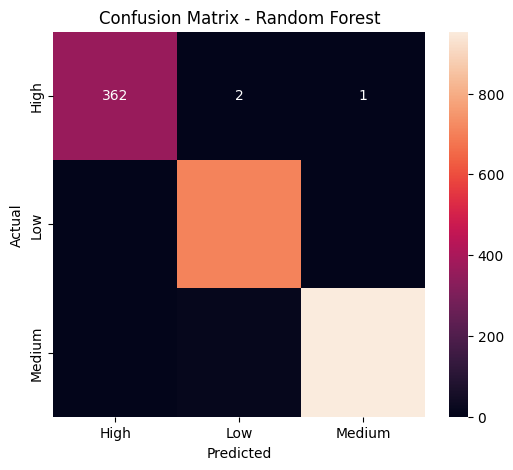

In [236]:
labels = ["High", "Low", "Medium"]

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels = labels
)

plt.figure(figsize = (6,5))

sns.heatmap(
    cm_rf,
    annot = True,
    fmt = "d",
    xticklabels = labels,
    yticklabels = labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()

Random Forest achieved an accuracy of approximately 99.12% on the test dataset. Out of 2,039 test records, approximately 2,021 were classified correctly and 18 were misclassified. The classification report shows strong precision, recall, and F1-scores across the High, Low, and Medium profitability categories. However, these results should be interpreted cautiously because the profitability categories are derived from profit margin and Product Name is strongly associated with the target.

The high model performance should be interpreted in the context of the dataset because Product Name has a very strong relationship with the Profitability Category.

## 14. Final Business Insights

1. **Sales and profitability:** The business generated total sales of 141,783.63 and gross profit of 93,442.80, with an overall average row-level profit margin of approximately 66.51%.

2. **Product performance:** Triple Dazzle Caramel generated the highest sales, while Scrumdiddlyumptious generated the highest gross profit. These products are important contributors to overall business performance.

3. **Division performance:** Chocolate is the dominant division, contributing the majority of sales and gross profit. The Other division has a lower aggregated profit margin and deserves further cost and pricing review.

4. **Regional performance:** Pacific generated the highest sales and gross profit, while Interior recorded the highest profit margin. This shows that the region with the highest revenue does not necessarily have the highest margin.

5. **Time-based performance:** Sales increased from 57,956.20 in 2024 to 83,827.43 in 2025, representing approximately 44.64% growth. Gross profit also increased by approximately 44.92%.

6. **Cost structure:** Kazookles is a priority for cost review because of its low profit margin. Milk Chocolate and Triple Dazzle Caramel are candidates for pricing review because of their sales contribution and comparatively lower margins than the product-level median.

7. **Geographic concentration:** California has the highest order count among the states analyzed. The business may monitor its dependence on major markets while exploring opportunities in other regions.

8. **Machine learning:** Random Forest achieved the highest observed test accuracy at approximately 99.12%, followed by Decision Tree at 97.30% and Logistic Regression at 93.18%. These results should be interpreted cautiously because Product Name is strongly associated with the profitability category. 

Overall, the analysis identifies key products, divisions, regions, and periods contributing to business performance. It also highlights products for further pricing and cost investigation. The results can support better-informed business decisions, but proposed actions should be validated using additional operational and market information.


## 15. Limitations

1. **Dataset scope:** The analysis is based on the available Nassau Candy Distributor dataset. The findings may not represent the complete business situation.

2. **Shipping date inconsistencies:** The shipping dates extend beyond the order dates by unusually long periods. This may indicate a data-quality issue, so shipping-related conclusions should be treated cautiously until the dates are verified.

3. **Limited business information:** The dataset does not include details such as customer satisfaction, competitor prices, marketing expenses, inventory availability, or market demand. Therefore, these factors could not be fully considered.

4. **Product review assumptions:** Products were flagged for pricing, cost renegotiation, or discontinuation review using median-based thresholds. These flags are preliminary and should not be treated as final business decisions.

5. **Machine-learning limitations:** Product Name is strongly associated with the profitability category created from profit margin. This may contribute to the high model accuracy. Further testing is required to determine how well the models perform on unseen products or future data.

6. **Limited time period:** The dataset covers order dates from January 2024 to December 2025. Longer-term data would help confirm whether the observed trends continue.


## 16. Future Scope

1. **Improve data quality:** Verify order dates and shipping dates, investigate unusual records, and ensure that all date-related calculations are reliable.

2. **Enhance the interactive dashboard:** Improve the existing Streamlit dashboard with additional performance metrics, clearer visualizations, and regular data updates to support ongoing monitoring of sales, gross profit, profit margins, product performance, and regional trends.

3. **Improve profitability prediction:** Evaluate additional machine-learning approaches and test them using time-based validation and suitable data from unseen products.

4. **Enhance pricing analysis:** Combine product margins with competitor pricing, customer demand, and sales-volume information to identify more reliable pricing opportunities.

5. **Optimize cost management:** Investigate supplier costs, production expenses, and other cost components to identify potential cost-saving opportunities.

6. **Expand geographic analysis:** Use additional regional sales and market data to understand market concentration and identify opportunities for business expansion.

7. **Introduce regular performance monitoring:** Update the analysis as new sales data becomes available so that changes in profitability and product performance can be identified over time.


## 17. Project Conclusion

The project, *Product Line Profitability & Margin Performance Analysis for Nassau Candy Distributor*, used Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn to examine product profitability and business performance.

The analysis covered data cleaning, feature engineering, exploratory data analysis, product performance, division-wise and region-wise comparisons, time-based trends, cost structure diagnostics, and machine-learning classification.

The findings identified the major contributors to sales and gross profit, differences in profitability across divisions and regions, changes in business performance between 2024 and 2025, and products requiring further pricing or cost review.

Three machine-learning models were evaluated, with Random Forest achieving the highest observed test accuracy of approximately 99.12%. However, this result requires cautious interpretation because the profitability categories were derived from profit margins and Product Name is strongly associated with the target.

Overall, the project demonstrates how data analysis and machine learning can help summarize business performance and identify areas for further investigation. The findings can support decision-making when combined with verified data and additional business information.


## Streamlit Web Application Requirements

The project will include an interactive web application developed using Streamlit to present the profitability analysis results in an easy-to-understand dashboard.

### Dashboard Modules

**1. Product Profitability Overview**
- Product-level profit margin leaderboard.
- Product-wise gross profit contribution charts.
- Key performance indicators such as sales, gross profit, and profit margin.

**2. Division Performance Dashboard**
- Revenue versus gross profit comparison by division.
- Profit margin distribution across divisions.

**3. Cost vs Margin Diagnostics**
- Cost versus sales scatter plots.
- Identification of products with low profit margins.
- Preliminary margin-risk flags for further review.

**4. Profit Concentration Analysis**
- Pareto charts for sales and gross profit.
- Identification of products contributing a large share of total revenue and profit.
- Indicators showing dependence on major contributing products.

### User Capabilities

- **Date Range Selector:** Filter the analysis by order date.
- **Division Filter:** Select one or more divisions for comparison.
- **Margin Threshold Slider:** Filter products according to a selected profit margin threshold.
- **Product Search:** Search for products by name and examine their performance.

### Technologies

- Python
- Pandas
- Streamlit
- Plotly

### Expected Outcome

The application will provide an interactive interface for exploring product profitability, division performance, cost structure, and profit concentration. It will help users investigate business performance and identify areas that may require further review.